In [1]:
%pip install numpy pandas matplotlib scikit-learn gymnasium stable-baselines3

Note: you may need to restart the kernel to use updated packages.


In [7]:
%pip install --upgrade yfinance

Note: you may need to restart the kernel to use updated packages.


In [1]:
import yfinance as yf
from pathlib import Path

# Crear la carpeta data si todavía no existe
carpeta = Path("data")
carpeta.mkdir(exist_ok=True)

# Descargar precios diarios de SPY
datos = yf.download(
    "SPY",
    start="2015-01-01",
    end="2026-01-01",
    interval="1d",
    auto_adjust=True,
    multi_level_index=False,
    progress=False
)

# Comprobar que la descarga funcionó
if datos.empty:
    raise ValueError(
        "No se descargaron datos. Revisa tu conexión e intenta nuevamente."
    )

# Organizar las columnas como solicita la actividad
datos = datos.reset_index()

datos = datos.rename(columns={
    "Date": "timestamp",
    "Open": "open",
    "High": "high",
    "Low": "low",
    "Close": "close",
    "Volume": "volume"
})

datos = datos[
    ["timestamp", "open", "high", "low", "close", "volume"]
]

# Guardar el dataset en CSV
archivo = carpeta / "SPY_diario_2015_2025.csv"
datos.to_csv(archivo, index=False)

print("Número de registros:", len(datos))
print("Archivo guardado en:", archivo.resolve())

display(datos.head())

C:\Users\MSI\anaconda3\Lib\site-packages\pandas\core\computation\expressions.py:23: UserWarning: Pandas requires version '2.10.2' or newer of 'numexpr' (version '2.8.7' currently installed).
  from pandas.core.computation.check import NUMEXPR_INSTALLED
C:\Users\MSI\anaconda3\Lib\site-packages\pandas\core\arrays\masked.py:56: UserWarning: Pandas requires version '1.4.2' or newer of 'bottleneck' (version '1.3.7' currently installed).
  from pandas.core import (


Número de registros: 2766
Archivo guardado en: C:\Users\MSI\Documents\Actividad_RL_Inversion\data\SPY_diario_2015_2025.csv


,timestamp,open,high,low,close,volume
0,2015-01-02,170.050311,170.462295,168.237574,169.267532,121465900
1,2015-01-05,168.229349,168.394140,165.905769,166.210632,169632600
2,2015-01-06,166.515492,167.034595,163.854082,164.645096,209151400
3,2015-01-07,165.963447,167.034607,165.518510,166.696777,125346700
4,2015-01-08,168.097564,169.869101,168.081093,169.654861,147217800


In [5]:
import sys
import numpy as np
import pandas as pd
import scipy
import yfinance as yf

print("Python:", sys.executable)
print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)
print("SciPy:", scipy.__version__)
print("Bibliotecas importadas correctamente")

Python: C:\Users\MSI\anaconda3\python.exe
NumPy: 2.5.2
Pandas: 3.0.5
SciPy: 1.18.1
Bibliotecas importadas correctamente


## 1. Carga y revisión de los datos

Se utilizan datos diarios del activo SPY entre 2015 y 2025,
descargados desde Yahoo Finance mediante yfinance.

El dataset contiene fecha, precios ajustados de apertura,
máximo, mínimo y cierre, y volumen negociado.

Antes de construir el entorno de inversión, se revisan las fechas,
los valores faltantes, los registros duplicados y la validez
de los precios. Los datos se mantienen en orden cronológico.

In [4]:
import pandas as pd
import numpy as np
from pathlib import Path

# Leer el CSV que ya descargamos
ruta = Path("data") / "SPY_diario_2015_2025.csv"

datos = pd.read_csv(ruta, parse_dates=["timestamp"])

# Ordenar desde la fecha más antigua hasta la más reciente
datos = datos.sort_values("timestamp").reset_index(drop=True)

print("Número de registros:", len(datos))
print("Primera fecha:", datos["timestamp"].min())
print("Última fecha:", datos["timestamp"].max())

display(datos.head())

Número de registros: 2766
Primera fecha: 2015-01-02 00:00:00
Última fecha: 2025-12-31 00:00:00


,timestamp,open,high,low,close,volume
0,2015-01-02,170.050311,170.462295,168.237574,169.267532,121465900
1,2015-01-05,168.229349,168.394140,165.905769,166.210632,169632600
2,2015-01-06,166.515492,167.034595,163.854082,164.645096,209151400
3,2015-01-07,165.963447,167.034607,165.518510,166.696777,125346700
4,2015-01-08,168.097564,169.869101,168.081093,169.654861,147217800


In [6]:
print("Valores faltantes por columna:")
display(datos.isna().sum())

print(
    "Número de fechas duplicadas:",
    datos["timestamp"].duplicated().sum()
)

print(
    "Número de precios de cierre menores o iguales a cero:",
    (datos["close"] <= 0).sum()
)

print("Tipos de datos:")
display(datos.dtypes)

Valores faltantes por columna:


timestamp    0
open         0
high         0
low          0
close        0
volume       0
dtype: int64

Número de fechas duplicadas: 0
Número de precios de cierre menores o iguales a cero: 0
Tipos de datos:


timestamp    datetime64[us]
open                float64
high                float64
low                 float64
close               float64
volume                int64
dtype: object

In [8]:
resultados = Path("results")
resultados.mkdir(exist_ok=True)

print("Carpeta de resultados:", resultados.resolve())

Carpeta de resultados: C:\Users\MSI\Documents\Actividad_RL_Inversion\results


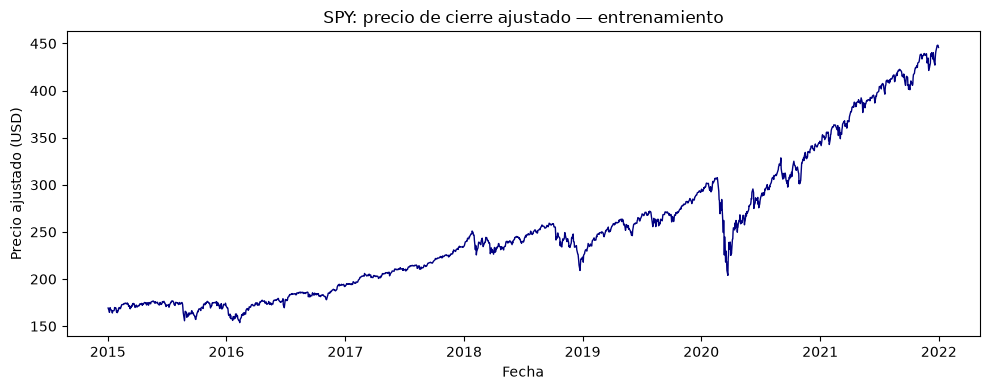

In [10]:
import matplotlib.pyplot as plt

# Seleccionar únicamente el período de entrenamiento
datos_entrenamiento = datos[
    datos["timestamp"] < "2022-01-01"
].copy()

fig, ax = plt.subplots(figsize=(10, 4))

ax.plot(
    datos_entrenamiento["timestamp"],
    datos_entrenamiento["close"],
    color="navy",
    linewidth=1
)

ax.set_title("SPY: precio de cierre ajustado — entrenamiento")
ax.set_xlabel("Fecha")
ax.set_ylabel("Precio ajustado (USD)")

fig.tight_layout()

fig.savefig(
    resultados / "01_precio_entrenamiento.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [12]:
datos_entrenamiento["retorno"] = (
    datos_entrenamiento["close"].pct_change(fill_method=None)
)

display(
    datos_entrenamiento[
        ["timestamp", "close", "retorno"]
    ].head()
)

print("Resumen de los retornos diarios:")
display(datos_entrenamiento["retorno"].describe())

,timestamp,close,retorno
0,2015-01-02,169.267532,NaN
1,2015-01-05,166.210632,-0.018060
2,2015-01-06,164.645096,-0.009419
3,2015-01-07,166.696777,0.012461
4,2015-01-08,169.654861,0.017745


Resumen de los retornos diarios:


count    1762.000000
mean        0.000612
std         0.011134
min        -0.109424
25%        -0.003218
50%         0.000668
75%         0.005501
max         0.090603
Name: retorno, dtype: float64

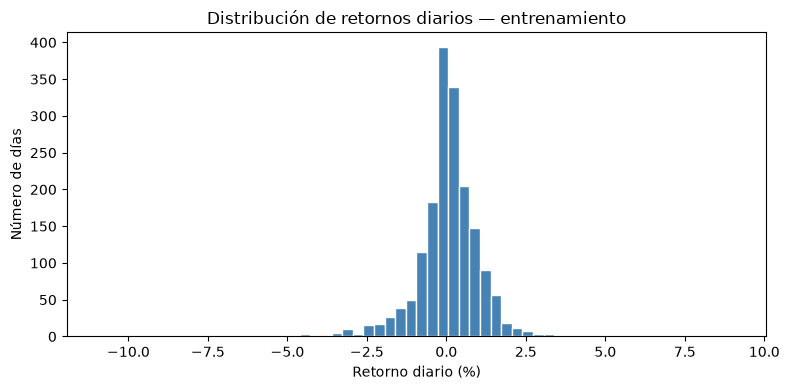

In [14]:
fig, ax = plt.subplots(figsize=(8, 4))

ax.hist(
    datos_entrenamiento["retorno"].dropna() * 100,
    bins=60,
    color="steelblue",
    edgecolor="white"
)

ax.set_title("Distribución de retornos diarios — entrenamiento")
ax.set_xlabel("Retorno diario (%)")
ax.set_ylabel("Número de días")

fig.tight_layout()
fig.savefig(
    resultados / "02_distribucion_retornos.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [16]:
# Trabajar sobre una copia del dataset
datos_indicadores = datos.copy()

# Retorno del último día
datos_indicadores["retorno"] = (
    datos_indicadores["close"].pct_change(fill_method=None)
)

# Media de los últimos 20 precios de cierre
datos_indicadores["media_20"] = (
    datos_indicadores["close"].rolling(window=20).mean()
)

# Distancia relativa del precio respecto a la media
datos_indicadores["distancia_media"] = (
    datos_indicadores["close"] / datos_indicadores["media_20"] - 1
)

# Desviación estándar de los últimos 20 retornos diarios
datos_indicadores["volatilidad_20"] = (
    datos_indicadores["retorno"].rolling(window=20).std()
)

display(
    datos_indicadores[
        ["timestamp", "close", "retorno",
         "media_20", "distancia_media", "volatilidad_20"]
    ].head(25)
)

,timestamp,close,retorno,media_20,distancia_media,volatilidad_20
0,2015-01-02,169.267532,NaN,NaN,NaN,NaN
1,2015-01-05,166.210632,-0.018060,NaN,NaN,NaN
2,2015-01-06,164.645096,-0.009419,NaN,NaN,NaN
3,2015-01-07,166.696777,0.012461,NaN,NaN,NaN
4,2015-01-08,169.654861,0.017745,NaN,NaN,NaN
5,2015-01-09,168.295242,-0.008014,NaN,NaN,NaN
6,2015-01-12,166.976913,-0.007833,NaN,NaN,NaN
7,2015-01-13,166.507263,-0.002813,NaN,NaN,NaN
8,2015-01-14,165.501968,-0.006038,NaN,NaN,NaN
9,2015-01-15,163.985886,-0.009161,NaN,NaN,NaN


In [18]:
variables_mercado = [
    "retorno",
    "distancia_media",
    "volatilidad_20"
]

datos_modelo = datos_indicadores.dropna(
    subset=variables_mercado
).reset_index(drop=True)

# Verificar que los indicadores sean números finitos
assert np.isfinite(
    datos_modelo[variables_mercado].to_numpy()
).all(), "Hay indicadores infinitos o no válidos."

print("Registros originales:", len(datos))
print("Registros con indicadores completos:", len(datos_modelo))
print("Primera fecha utilizable:", datos_modelo["timestamp"].min())

display(datos_modelo.head())

Registros originales: 2766
Registros con indicadores completos: 2746
Primera fecha utilizable: 2015-02-02 00:00:00


,timestamp,open,high,low,close,volume,retorno,media_20,distancia_media,volatilidad_20
0,2015-02-02,164.834552,166.466003,163.030063,166.375366,163107000,0.012384,166.776675,-0.002406,0.011050
1,2015-02-03,167.265291,168.789635,166.894509,168.781387,124212900,0.014461,166.905212,0.011241,0.010766
2,2015-02-04,168.023302,169.226299,167.685472,168.138657,134306700,-0.003808,167.079890,0.006337,0.010557
3,2015-02-05,168.797896,169.984411,168.723742,169.836090,97953200,0.010095,167.236856,0.015542,0.010435
4,2015-02-06,170.198596,170.758900,168.847291,169.366394,125672000,-0.002766,167.222433,0.012821,0.009682


In [20]:
entrenamiento = datos_modelo[
    datos_modelo["timestamp"] < "2022-01-01"
].copy().reset_index(drop=True)

validacion = datos_modelo[
    (datos_modelo["timestamp"] >= "2022-01-01")
    & (datos_modelo["timestamp"] < "2024-01-01")
].copy().reset_index(drop=True)

prueba = datos_modelo[
    datos_modelo["timestamp"] >= "2024-01-01"
].copy().reset_index(drop=True)

resumen_periodos = pd.DataFrame([
    {
        "Periodo": nombre,
        "Registros": len(tabla),
        "Inicio": tabla["timestamp"].min(),
        "Fin": tabla["timestamp"].max()
    }
    for nombre, tabla in [
        ("Entrenamiento", entrenamiento),
        ("Validación", validacion),
        ("Prueba final", prueba)
    ]
])

display(resumen_periodos)

resumen_periodos.to_csv(
    resultados / "resumen_periodos.csv",
    index=False
)

,Periodo,Registros,Inicio,Fin
0,Entrenamiento,1743,2015-02-02,2021-12-31
1,Validación,501,2022-01-03,2023-12-29
2,Prueba final,502,2024-01-02,2025-12-31


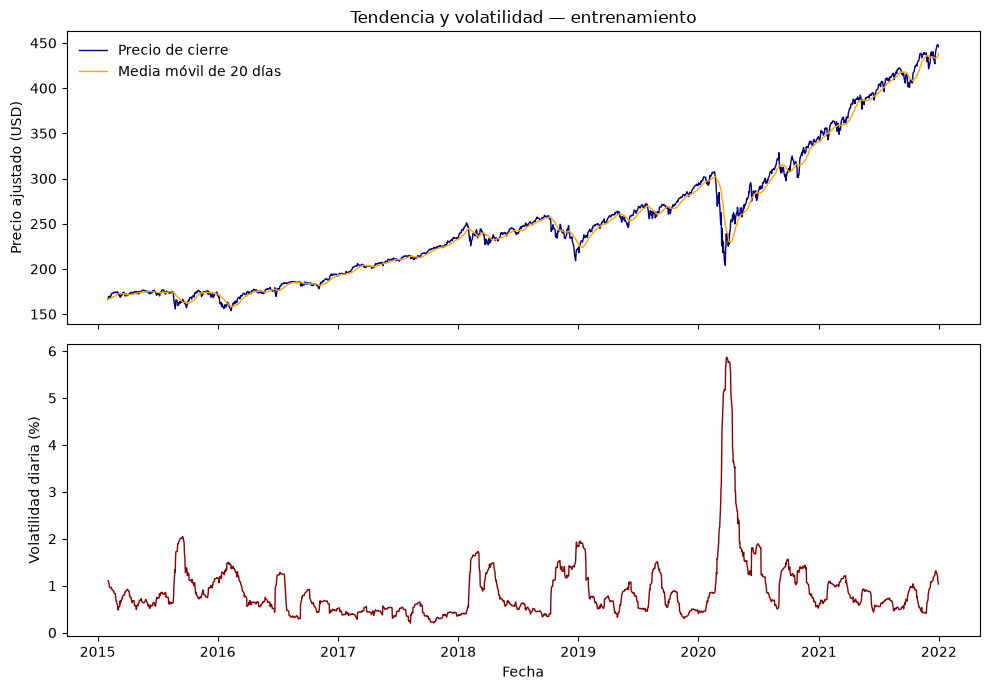

In [22]:
fig, axes = plt.subplots(
    2, 1,
    figsize=(10, 7),
    sharex=True
)

# Precio y media móvil
axes[0].plot(
    entrenamiento["timestamp"],
    entrenamiento["close"],
    label="Precio de cierre",
    linewidth=1,
    color="navy"
)

axes[0].plot(
    entrenamiento["timestamp"],
    entrenamiento["media_20"],
    label="Media móvil de 20 días",
    linewidth=1,
    color="orange"
)

axes[0].set_ylabel("Precio ajustado (USD)")
axes[0].set_title("Tendencia y volatilidad — entrenamiento")
axes[0].legend(frameon=False)

# Volatilidad expresada como porcentaje diario
axes[1].plot(
    entrenamiento["timestamp"],
    entrenamiento["volatilidad_20"] * 100,
    color="darkred",
    linewidth=1
)

axes[1].set_xlabel("Fecha")
axes[1].set_ylabel("Volatilidad diaria (%)")

fig.tight_layout()
fig.savefig(
    resultados / "03_tendencia_volatilidad.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [24]:
entrenamiento.to_csv(
    Path("data") / "entrenamiento.csv", index=False
)

validacion.to_csv(
    Path("data") / "validacion.csv", index=False
)

prueba.to_csv(
    Path("data") / "prueba.csv", index=False
)

print("Los tres períodos quedaron guardados en la carpeta data.")

Los tres períodos quedaron guardados en la carpeta data.


In [28]:
import sys
print(sys.executable)

C:\Users\MSI\anaconda3\python.exe


In [1]:
import sys
print(sys.executable)

C:\Users\MSI\anaconda3\envs\rl_inversion\python.exe


In [3]:
import numpy as np
import pandas as pd
import scipy
import gymnasium as gym

from gymnasium import spaces
from sklearn.preprocessing import StandardScaler
from stable_baselines3.common.env_checker import check_env

print("NumPy:", np.__version__)
print("SciPy:", scipy.__version__)
print("Importaciones correctas.")

NumPy: 1.26.4
SciPy: 1.13.1
Importaciones correctas.


In [5]:
from pathlib import Path
import matplotlib.pyplot as plt

entrenamiento = pd.read_csv(
    Path("data") / "entrenamiento.csv",
    parse_dates=["timestamp"]
)

validacion = pd.read_csv(
    Path("data") / "validacion.csv",
    parse_dates=["timestamp"]
)

prueba = pd.read_csv(
    Path("data") / "prueba.csv",
    parse_dates=["timestamp"]
)

resultados = Path("results")
resultados.mkdir(exist_ok=True)

print("Registros de entrenamiento:", len(entrenamiento))
print("Registros de validación:", len(validacion))
print("Registros de prueba:", len(prueba))

display(entrenamiento.head())

Registros de entrenamiento: 1743
Registros de validación: 501
Registros de prueba: 502


,timestamp,open,high,low,close,volume,retorno,media_20,distancia_media,volatilidad_20
0,2015-02-02,164.834552,166.466003,163.030063,166.375366,163107000,0.012384,166.776675,-0.002406,0.011050
1,2015-02-03,167.265291,168.789635,166.894509,168.781387,124212900,0.014461,166.905212,0.011241,0.010766
2,2015-02-04,168.023302,169.226299,167.685472,168.138657,134306700,-0.003808,167.079890,0.006337,0.010557
3,2015-02-05,168.797896,169.984411,168.723742,169.836090,97953200,0.010095,167.236856,0.015542,0.010435
4,2015-02-06,170.198596,170.758900,168.847291,169.366394,125672000,-0.002766,167.222433,0.012821,0.009682


In [7]:
variables_mercado = [
    "retorno",
    "distancia_media",
    "volatilidad_20"
]

escalador = StandardScaler()

escalador.fit(entrenamiento[variables_mercado])

print("Normalizador preparado con los datos de entrenamiento.")

Normalizador preparado con los datos de entrenamiento.


In [13]:
import numpy as np
import pandas as pd
import gymnasium as gym

from pathlib import Path
from gymnasium import spaces
from sklearn.preprocessing import StandardScaler
from stable_baselines3.common.env_checker import check_env

# Recuperar los datos guardados
entrenamiento = pd.read_csv(
    Path("data") / "entrenamiento.csv",
    parse_dates=["timestamp"]
)

# Preparar el normalizador
variables_mercado = [
    "retorno",
    "distancia_media",
    "volatilidad_20"
]

escalador = StandardScaler()
escalador.fit(entrenamiento[variables_mercado])

print("Datos y normalizador preparados.")

Datos y normalizador preparados.


In [15]:
class EntornoInversion(gym.Env):

    metadata = {"render_modes": []}

    def __init__(
        self,
        tabla,
        escalador,
        capital_inicial=100_000.0,
        costo=0.001,
        penalizacion=0.0
    ):
        super().__init__()

        self.tabla = tabla.copy().reset_index(drop=True)

        if len(self.tabla) < 2:
            raise ValueError("Se necesitan al menos dos días.")

        columnas = [
            "open", "close", "retorno",
            "distancia_media", "volatilidad_20"
        ]

        if not np.isfinite(self.tabla[columnas].to_numpy()).all():
            raise ValueError("Hay datos faltantes o no válidos.")

        if (self.tabla[["open", "close"]] <= 0).any().any():
            raise ValueError("Los precios deben ser positivos.")

        if not 0 <= costo < 1:
            raise ValueError("El costo debe estar entre 0 y 1.")

        self.capital_inicial = float(capital_inicial)
        self.costo = float(costo)
        self.penalizacion = float(penalizacion)

        self.indicadores = escalador.transform(
            self.tabla[
                ["retorno", "distancia_media", "volatilidad_20"]
            ]
        ).astype(np.float32)

        self.proporciones = [0.0, 0.5, 1.0]
        self.action_space = spaces.Discrete(3)

        self.observation_space = spaces.Box(
            low=np.array(
                [-np.inf, -np.inf, -np.inf, 0.0],
                dtype=np.float32
            ),
            high=np.array(
                [np.inf, np.inf, np.inf, 1.0],
                dtype=np.float32
            ),
            dtype=np.float32
        )

    def _observacion(self):
        precio = float(self.tabla.loc[self.t, "close"])
        invertido = self.participaciones * precio

        posicion = np.clip(
            invertido / self.capital, 0.0, 1.0
        )

        return np.array(
            [*self.indicadores[self.t], posicion],
            dtype=np.float32
        )

    def reset(self, seed=None, options=None):
        super().reset(seed=seed)

        self.t = 0
        self.efectivo = self.capital_inicial
        self.participaciones = 0.0
        self.capital = self.capital_inicial
        self.costos_totales = 0.0
        self.finalizado = False

        self.historial = [{
            "fecha": self.tabla.loc[0, "timestamp"],
            "capital": self.capital,
            "accion": -1,
            "objetivo": 0.0,
            "posicion": 0.0,
            "costo": 0.0,
            "importe_operado": 0.0,
            "retorno_neto": 0.0,
            "recompensa": 0.0
        }]

        return self._observacion(), {"capital": self.capital}

    def step(self, action):
        if self.finalizado:
            raise RuntimeError("El episodio terminó. Ejecuta reset().")

        if not self.action_space.contains(action):
            raise ValueError("La acción debe ser 0, 1 o 2.")

        action = int(action)
        objetivo = self.proporciones[action]
        capital_anterior = self.capital

        # Observar hoy y ejecutar en la apertura de mañana
        dia_siguiente = self.t + 1
        apertura = float(self.tabla.loc[dia_siguiente, "open"])
        cierre = float(self.tabla.loc[dia_siguiente, "close"])

        invertido_apertura = self.participaciones * apertura
        capital_apertura = self.efectivo + invertido_apertura

        diferencia = (
            objetivo * capital_apertura - invertido_apertura
        )

        if diferencia >= 0:
            importe = diferencia / (1 + objetivo * self.costo)
        else:
            importe = diferencia / (1 - objetivo * self.costo)

        costo_operacion = abs(importe) * self.costo

        self.efectivo -= importe + costo_operacion
        self.participaciones += importe / apertura

        self.efectivo = max(0.0, self.efectivo)
        self.participaciones = max(0.0, self.participaciones)
        self.costos_totales += costo_operacion

        self.capital = (
            self.efectivo + self.participaciones * cierre
        )

        retorno_neto = self.capital / capital_anterior - 1

        recompensa = (
            retorno_neto
            - self.penalizacion * max(0.0, -retorno_neto)
        )

        self.t = dia_siguiente
        self.finalizado = self.t >= len(self.tabla) - 1

        posicion = self.participaciones * cierre / self.capital

        info = {
            "fecha": self.tabla.loc[self.t, "timestamp"],
            "capital": self.capital,
            "accion": action,
            "objetivo": objetivo,
            "posicion": float(posicion),
            "costo": float(costo_operacion),
            "importe_operado": float(abs(importe)),
            "retorno_neto": float(retorno_neto),
            "recompensa": float(recompensa)
        }

        self.historial.append(info.copy())

        return (
            self._observacion(),
            float(recompensa),
            bool(self.finalizado),
            False,
            info
        )


print("La clase EntornoInversion quedó definida.")

La clase EntornoInversion quedó definida.


In [17]:
entorno_revision = EntornoInversion(
    entrenamiento,
    escalador
)

check_env(entorno_revision, warn=True)

print("Entorno compatible con Stable-Baselines3.")

Entorno compatible con Stable-Baselines3.


In [19]:
def ejecutar_estrategia(tabla, estrategia, semilla=42):
    entorno = EntornoInversion(tabla, escalador)
    observacion, info = entorno.reset(seed=semilla)

    generador = np.random.default_rng(semilla)
    terminado = False

    while not terminado:

        if estrategia == "efectivo":
            accion = 0

        elif estrategia == "comprar_mantener":
            accion = 2

        elif estrategia == "aleatorio":
            accion = int(generador.integers(0, 3))

        else:
            raise ValueError("Estrategia no reconocida.")

        observacion, recompensa, terminated, truncated, info = (
            entorno.step(accion)
        )

        terminado = terminated or truncated

    return pd.DataFrame(entorno.historial)


print("Función preparada.")

Función preparada.


In [21]:
historial_efectivo = ejecutar_estrategia(
    entrenamiento,
    "efectivo"
)

assert np.allclose(
    historial_efectivo["capital"],
    100_000.0
)

assert np.isclose(
    historial_efectivo["costo"].sum(),
    0.0
)

print("Comprobación correcta: el capital permanece en 100 000.")

Comprobación correcta: el capital permanece en 100 000.


In [23]:
historial_compra = ejecutar_estrategia(
    entrenamiento,
    "comprar_mantener"
)

precio_compra = float(entrenamiento.iloc[1]["open"])
precio_final = float(entrenamiento.iloc[-1]["close"])

capital_esperado = (
    100_000 / (1 + 0.001)
    * precio_final / precio_compra
)

capital_obtenido = historial_compra["capital"].iloc[-1]

assert np.isclose(
    capital_obtenido,
    capital_esperado
)

print("Comprobación de comprar y mantener correcta.")
print(f"Capital obtenido: {capital_obtenido:,.2f} USD")
print(f"Capital esperado: {capital_esperado:,.2f} USD")

Comprobación de comprar y mantener correcta.
Capital obtenido: 266,251.62 USD
Capital esperado: 266,251.62 USD


In [25]:
def calcular_metricas(historial):
    capital = historial["capital"]

    retorno = capital.iloc[-1] / capital.iloc[0] - 1

    maximo_previo = capital.cummax()
    drawdown = capital / maximo_previo - 1
    maximo_drawdown = -drawdown.min()

    return {
        "Capital final (USD)": float(capital.iloc[-1]),
        "Retorno acumulado (%)": float(retorno * 100),
        "Máximo drawdown (%)": float(maximo_drawdown * 100),
        "Costos totales (USD)": float(historial["costo"].sum())
    }


print("Función de métricas preparada.")

Función de métricas preparada.


In [27]:
validacion = pd.read_csv(
    Path("data") / "validacion.csv",
    parse_dates=["timestamp"]
)

historial_compra_val = ejecutar_estrategia(
    validacion,
    "comprar_mantener"
)

historial_aleatorio_val = ejecutar_estrategia(
    validacion,
    "aleatorio",
    semilla=42
)

tabla_referencia = pd.DataFrame(
    [
        calcular_metricas(historial_compra_val),
        calcular_metricas(historial_aleatorio_val)
    ],
    index=[
        "Comprar y mantener",
        "Aleatorio — semilla 42"
    ]
)

display(tabla_referencia.round(2))

,Capital final (USD),Retorno acumulado (%),Máximo drawdown (%),Costos totales (USD)
Comprar y mantener,102222.87,2.22,24.81,99.9
Aleatorio — semilla 42,55876.80,-44.12,46.04,15819.0


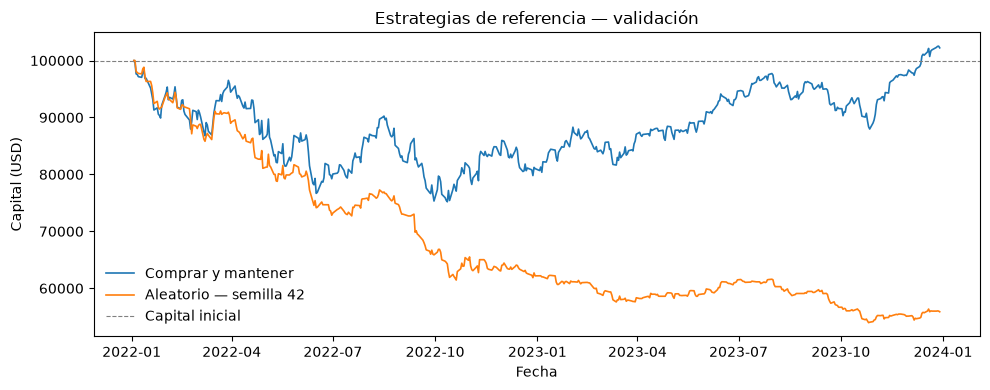

In [29]:
import matplotlib.pyplot as plt

resultados = Path("results")
resultados.mkdir(exist_ok=True)

fig, ax = plt.subplots(figsize=(10, 4))

ax.plot(
    historial_compra_val["fecha"],
    historial_compra_val["capital"],
    label="Comprar y mantener",
    linewidth=1.2
)

ax.plot(
    historial_aleatorio_val["fecha"],
    historial_aleatorio_val["capital"],
    label="Aleatorio — semilla 42",
    linewidth=1.2
)

ax.axhline(
    100_000,
    color="gray",
    linestyle="--",
    linewidth=0.8,
    label="Capital inicial"
)

ax.set_title("Estrategias de referencia — validación")
ax.set_xlabel("Fecha")
ax.set_ylabel("Capital (USD)")
ax.legend(frameon=False)

fig.tight_layout()
fig.savefig(
    resultados / "04_referencias_validacion.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [31]:
metricas_aleatorias = []

for semilla in range(10):
    historial = ejecutar_estrategia(
        validacion,
        "aleatorio",
        semilla=semilla
    )

    metricas = calcular_metricas(historial)
    metricas["Semilla"] = semilla

    metricas_aleatorias.append(metricas)

tabla_aleatorios = pd.DataFrame(
    metricas_aleatorias
).set_index("Semilla")

display(tabla_aleatorios.round(2))

print("Promedio y desviación estándar entre las 10 ejecuciones:")

display(
    tabla_aleatorios.agg(["mean", "std"]).round(2)
)

,Capital final (USD),Retorno acumulado (%),Máximo drawdown (%),Costos totales (USD)
Semilla,,,,
0,77064.69,-22.94,30.19,18575.83
1,75701.96,-24.30,27.87,18631.64
2,63608.29,-36.39,38.29,15631.32
3,83818.55,-16.18,25.39,17400.00
4,73947.26,-26.05,29.20,18583.60
5,85484.74,-14.52,20.57,19932.84
6,89598.16,-10.40,16.17,21069.88
7,96149.62,-3.85,16.61,18782.04
8,83854.76,-16.15,25.26,19643.31


Promedio y desviación estándar entre las 10 ejecuciones:


,Capital final (USD),Retorno acumulado (%),Máximo drawdown (%),Costos totales (USD)
mean,80598.31,-19.40,25.63,18777.88
std,9139.79,9.14,6.64,1483.19


In [33]:
tabla_referencia.to_csv(
    resultados / "metricas_referencia_validacion.csv"
)

tabla_aleatorios.to_csv(
    resultados / "metricas_aleatorios_validacion.csv"
)

historial_compra_val.to_csv(
    resultados / "historial_compra_validacion.csv",
    index=False
)

historial_aleatorio_val.to_csv(
    resultados / "historial_aleatorio_validacion.csv",
    index=False
)

print("Métricas, historiales y figura guardados en results.")

Métricas, historiales y figura guardados en results.


In [35]:
from stable_baselines3 import DQN
from stable_baselines3.common.monitor import Monitor
import joblib
import json

modelos = Path("models")
modelos.mkdir(exist_ok=True)

resultados = Path("results")
resultados.mkdir(exist_ok=True)

print("Carpetas preparadas.")

Carpetas preparadas.


In [37]:
entorno_dqn = EntornoInversion(
    entrenamiento,
    escalador,
    capital_inicial=100_000,
    costo=0.001,
    penalizacion=0.0
)

entorno_dqn = Monitor(
    entorno_dqn,
    filename=str(resultados / "dqn_v1")
)

print("Entorno de entrenamiento preparado.")

Entorno de entrenamiento preparado.


In [39]:
parametros_dqn = {
    "learning_rate": 0.0001,
    "buffer_size": 50_000,
    "learning_starts": 2_000,
    "batch_size": 64,
    "gamma": 0.99,
    "train_freq": 4,
    "gradient_steps": 1,
    "target_update_interval": 1_000,
    "exploration_fraction": 0.30,
    "exploration_initial_eps": 1.0,
    "exploration_final_eps": 0.05,
    "policy_kwargs": {"net_arch": [64, 64]},
    "seed": 42,
    "device": "cpu"
}

modelo_v1 = DQN(
    "MlpPolicy",
    entorno_dqn,
    verbose=1,
    **parametros_dqn
)

print("DQN creado.")

Using cpu device
Wrapping the env in a DummyVecEnv.
DQN creado.


In [41]:
PASOS_ENTRENAMIENTO = 50_000

modelo_v1.learn(
    total_timesteps=PASOS_ENTRENAMIENTO,
    log_interval=1
)

print("Primer entrenamiento terminado.")

----------------------------------
| rollout/            |          |
|    ep_len_mean      | 1.74e+03 |
|    ep_rew_mean      | -0.207   |
|    exploration_rate | 0.89     |
| time/               |          |
|    episodes         | 1        |
|    fps              | 8205     |
|    time_elapsed     | 0        |
|    total_timesteps  | 1742     |
----------------------------------
----------------------------------
| rollout/            |          |
|    ep_len_mean      | 1.74e+03 |
|    ep_rew_mean      | -0.237   |
|    exploration_rate | 0.779    |
| time/               |          |
|    episodes         | 2        |
|    fps              | 3417     |
|    time_elapsed     | 1        |
|    total_timesteps  | 3484     |
| train/              |          |
|    learning_rate    | 0.0001   |
|    loss             | 0.000191 |
|    n_updates        | 370      |
----------------------------------
----------------------------------
| rollout/            |          |
|    ep_len_mean    

In [43]:
modelo_v1.save(str(modelos / "dqn_v1"))

joblib.dump(
    escalador,
    modelos / "escalador.joblib"
)

print("Modelo y normalizador guardados.")

Modelo y normalizador guardados.


In [45]:
def evaluar_dqn(modelo, tabla):
    entorno = EntornoInversion(
        tabla,
        escalador,
        capital_inicial=100_000,
        costo=0.001,
        penalizacion=0.0
    )

    observacion, info = entorno.reset(seed=42)
    terminado = False

    while not terminado:
        accion, _ = modelo.predict(
            observacion,
            deterministic=True
        )

        accion = int(np.asarray(accion).item())

        observacion, recompensa, terminated, truncated, info = (
            entorno.step(accion)
        )

        terminado = terminated or truncated

    return pd.DataFrame(entorno.historial)


print("Función de evaluación preparada.")

Función de evaluación preparada.


In [47]:
historial_dqn_v1 = evaluar_dqn(
    modelo_v1,
    validacion
)

comparacion_v1 = pd.DataFrame(
    [
        calcular_metricas(historial_compra_val),
        calcular_metricas(historial_aleatorio_val),
        calcular_metricas(historial_dqn_v1)
    ],
    index=[
        "Comprar y mantener",
        "Aleatorio — semilla 42",
        "DQN versión 1"
    ]
)

display(comparacion_v1.round(2))

comparacion_v1.to_csv(
    resultados / "comparacion_dqn_v1_validacion.csv"
)

historial_dqn_v1.to_csv(
    resultados / "historial_dqn_v1_validacion.csv",
    index=False
)

,Capital final (USD),Retorno acumulado (%),Máximo drawdown (%),Costos totales (USD)
Comprar y mantener,102222.87,2.22,24.81,99.90
Aleatorio — semilla 42,55876.80,-44.12,46.04,15819.00
DQN versión 1,79023.35,-20.98,24.57,16567.35


In [49]:
frecuencias_v1 = (
    historial_dqn_v1.iloc[1:]["accion"]
    .value_counts(normalize=True)
    .reindex([0, 1, 2], fill_value=0)
    * 100
)

frecuencias_v1.index = [
    "0 % invertido",
    "50 % invertido",
    "100 % invertido"
]

print("Porcentaje de decisiones:")
display(frecuencias_v1.round(2))

Porcentaje de decisiones:


0 % invertido      32.6
50 % invertido     27.6
100 % invertido    39.8
Name: proportion, dtype: float64

In [51]:
decisiones_v1 = historial_dqn_v1.iloc[1:].copy()

cambios_v1 = (
    decisiones_v1["accion"]
    .diff()
    .fillna(0)
    .ne(0)
    .sum()
)

dias_con_operacion = (
    decisiones_v1["importe_operado"] > 0.01
).sum()

print("Decisiones realizadas:", len(decisiones_v1))
print("Cambios de acción:", cambios_v1)
print("Días con operaciones mayores a 0.01 USD:", dias_con_operacion)

print(
    "Costos como porcentaje del capital inicial:",
    round(historial_dqn_v1["costo"].sum() / 100_000 * 100, 2),
    "%"
)

Decisiones realizadas: 500
Cambios de acción: 297
Días con operaciones mayores a 0.01 USD: 337
Costos como porcentaje del capital inicial: 16.57 %


In [53]:
class EntornoInversionRotacion(EntornoInversion):

    def __init__(self, tabla, escalador, eta=0.001, **kwargs):
        super().__init__(tabla, escalador, **kwargs)
        self.eta = float(eta)

    def step(self, action):
        capital_anterior = self.capital

        observacion, recompensa, terminated, truncated, info = (
            super().step(action)
        )

        rotacion = (
            info["importe_operado"] / capital_anterior
        )

        recompensa_modificada = (
            recompensa - self.eta * rotacion
        )

        info["rotacion"] = float(rotacion)
        info["recompensa"] = float(recompensa_modificada)

        self.historial[-1].update(info)

        return (
            observacion,
            float(recompensa_modificada),
            terminated,
            truncated,
            info
        )


print("Entorno con penalización de rotación preparado.")

Entorno con penalización de rotación preparado.


In [55]:
env_original = EntornoInversion(
    entrenamiento, escalador
)

env_rotacion = EntornoInversionRotacion(
    entrenamiento, escalador, eta=0.001
)

env_original.reset(seed=42)
env_rotacion.reset(seed=42)

for accion in [0, 1, 2, 1, 0]:
    env_original.step(accion)
    env_rotacion.step(accion)

    assert np.isclose(
        env_original.capital,
        env_rotacion.capital
    )

print("Correcto: las mismas acciones producen el mismo capital.")

Correcto: las mismas acciones producen el mismo capital.


In [57]:
ETA_ROTACION = 0.001

entorno_v2 = EntornoInversionRotacion(
    entrenamiento,
    escalador,
    eta=ETA_ROTACION,
    capital_inicial=100_000,
    costo=0.001,
    penalizacion=0.0
)

check_env(entorno_v2, warn=True)

entorno_v2 = Monitor(
    entorno_v2,
    filename=str(resultados / "dqn_v2")
)

modelo_v2 = DQN(
    "MlpPolicy",
    entorno_v2,
    verbose=1,
    **parametros_dqn
)

print("Segundo DQN creado.")

Using cpu device
Wrapping the env in a DummyVecEnv.
Segundo DQN creado.


In [59]:
modelo_v2.learn(
    total_timesteps=PASOS_ENTRENAMIENTO,
    log_interval=1
)

print("Segundo entrenamiento terminado.")

----------------------------------
| rollout/            |          |
|    ep_len_mean      | 1.74e+03 |
|    ep_rew_mean      | -0.973   |
|    exploration_rate | 0.89     |
| time/               |          |
|    episodes         | 1        |
|    fps              | 9151     |
|    time_elapsed     | 0        |
|    total_timesteps  | 1742     |
----------------------------------
----------------------------------
| rollout/            |          |
|    ep_len_mean      | 1.74e+03 |
|    ep_rew_mean      | -1.02    |
|    exploration_rate | 0.779    |
| time/               |          |
|    episodes         | 2        |
|    fps              | 3718     |
|    time_elapsed     | 0        |
|    total_timesteps  | 3484     |
| train/              |          |
|    learning_rate    | 0.0001   |
|    loss             | 0.000191 |
|    n_updates        | 370      |
----------------------------------
----------------------------------
| rollout/            |          |
|    ep_len_mean    

In [61]:
modelo_v2.save(str(modelos / "dqn_v2"))

configuracion_v2 = {
    "algoritmo": "DQN",
    "parametros": parametros_dqn,
    "pasos_realizados": int(modelo_v2.num_timesteps),
    "recompensa": "retorno neto menos penalización de rotación",
    "eta": ETA_ROTACION,
    "costo": 0.001,
    "capital_inicial": 100_000
}

with open(
    modelos / "configuracion_v2.json",
    "w",
    encoding="utf-8"
) as archivo:
    json.dump(
        configuracion_v2,
        archivo,
        indent=4,
        ensure_ascii=False
    )

print("Segunda versión guardada.")

Segunda versión guardada.


In [63]:
historial_dqn_v2 = evaluar_dqn(
    modelo_v2,
    validacion
)

comparacion_v2 = pd.DataFrame(
    [
        calcular_metricas(historial_compra_val),
        calcular_metricas(historial_aleatorio_val),
        calcular_metricas(historial_dqn_v1),
        calcular_metricas(historial_dqn_v2)
    ],
    index=[
        "Comprar y mantener",
        "Aleatorio — semilla 42",
        "DQN versión 1",
        "DQN versión 2"
    ]
)

display(comparacion_v2.round(2))

,Capital final (USD),Retorno acumulado (%),Máximo drawdown (%),Costos totales (USD)
Comprar y mantener,102222.87,2.22,24.81,99.90
Aleatorio — semilla 42,55876.80,-44.12,46.04,15819.00
DQN versión 1,79023.35,-20.98,24.57,16567.35
DQN versión 2,105625.65,5.63,16.71,14935.05


In [65]:
frecuencias_v2 = (
    historial_dqn_v2.iloc[1:]["accion"]
    .value_counts(normalize=True)
    .reindex([0, 1, 2], fill_value=0)
    * 100
)

frecuencias_v2.index = [
    "0 % invertido",
    "50 % invertido",
    "100 % invertido"
]

display(
    pd.DataFrame({
        "DQN v1 (%)": frecuencias_v1,
        "DQN v2 (%)": frecuencias_v2
    }).round(2)
)

comparacion_v2.to_csv(
    resultados / "comparacion_recompensas_validacion.csv"
)

historial_dqn_v2.to_csv(
    resultados / "historial_dqn_v2_validacion.csv",
    index=False
)

print("Comparación guardada.")

,DQN v1 (%),DQN v2 (%)
0 % invertido,32.6,28.8
50 % invertido,27.6,25.4
100 % invertido,39.8,45.8


Comparación guardada.


In [67]:
display(comparacion_v2.round(2))

,Capital final (USD),Retorno acumulado (%),Máximo drawdown (%),Costos totales (USD)
Comprar y mantener,102222.87,2.22,24.81,99.90
Aleatorio — semilla 42,55876.80,-44.12,46.04,15819.00
DQN versión 1,79023.35,-20.98,24.57,16567.35
DQN versión 2,105625.65,5.63,16.71,14935.05


In [69]:
def diagnostico_operaciones(historial):
    decisiones = historial.iloc[1:].copy()

    cambios = (
        decisiones["accion"]
        .diff()
        .fillna(0)
        .ne(0)
        .sum()
    )

    return {
        "Cambios de acción": int(cambios),
        "Días con operación > 0.01 USD": int(
            (decisiones["importe_operado"] > 0.01).sum()
        ),
        "Importe total operado (USD)": float(
            decisiones["importe_operado"].sum()
        ),
        "Costos totales (USD)": float(
            decisiones["costo"].sum()
        )
    }


diagnostico_versions = pd.DataFrame(
    [
        diagnostico_operaciones(historial_dqn_v1),
        diagnostico_operaciones(historial_dqn_v2)
    ],
    index=["DQN v1", "DQN v2"]
)

display(diagnostico_versions.round(2))

diagnostico_versions.to_csv(
    resultados / "diagnostico_operaciones_validacion.csv"
)

,Cambios de acción,Días con operación > 0.01 USD,Importe total operado (USD),Costos totales (USD)
DQN v1,297,337,16567346.81,16567.35
DQN v2,230,284,14935051.22,14935.05


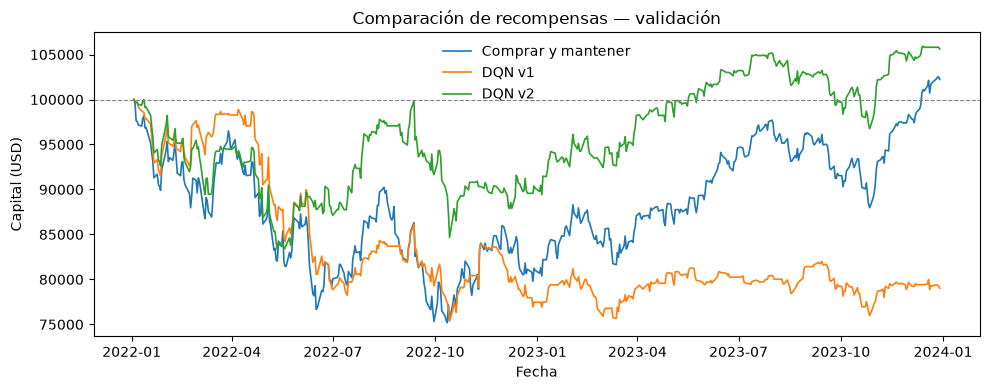

In [71]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(10, 4))

for nombre, historial in [
    ("Comprar y mantener", historial_compra_val),
    ("DQN v1", historial_dqn_v1),
    ("DQN v2", historial_dqn_v2)
]:
    ax.plot(
        historial["fecha"],
        historial["capital"],
        label=nombre,
        linewidth=1.2
    )

ax.axhline(
    100_000,
    color="gray",
    linestyle="--",
    linewidth=0.8
)

ax.set_title("Comparación de recompensas — validación")
ax.set_xlabel("Fecha")
ax.set_ylabel("Capital (USD)")
ax.legend(frameon=False)

fig.tight_layout()
fig.savefig(
    resultados / "07_comparacion_recompensas.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

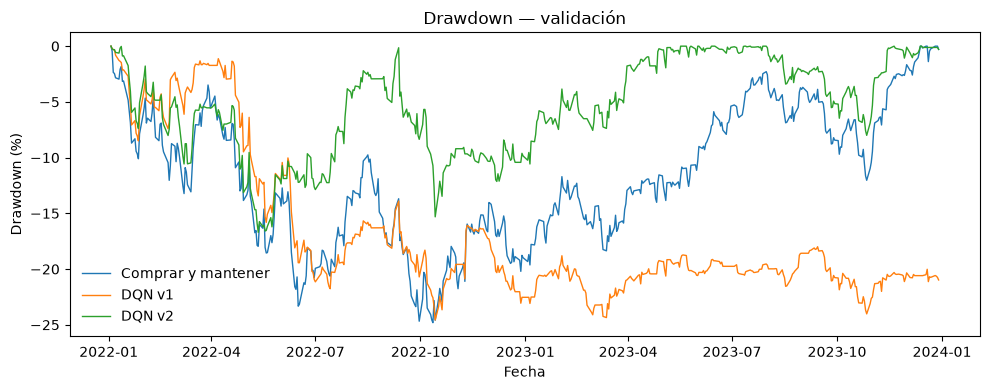

In [73]:
fig, ax = plt.subplots(figsize=(10, 4))

for nombre, historial in [
    ("Comprar y mantener", historial_compra_val),
    ("DQN v1", historial_dqn_v1),
    ("DQN v2", historial_dqn_v2)
]:
    capital = historial["capital"]
    drawdown = (capital / capital.cummax() - 1) * 100

    ax.plot(
        historial["fecha"],
        drawdown,
        label=nombre,
        linewidth=1
    )

ax.set_title("Drawdown — validación")
ax.set_xlabel("Fecha")
ax.set_ylabel("Drawdown (%)")
ax.legend(frameon=False)

fig.tight_layout()
fig.savefig(
    resultados / "08_drawdown_validacion.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [75]:
display(comparacion_v2.round(2))


,Capital final (USD),Retorno acumulado (%),Máximo drawdown (%),Costos totales (USD)
Comprar y mantener,102222.87,2.22,24.81,99.90
Aleatorio — semilla 42,55876.80,-44.12,46.04,15819.00
DQN versión 1,79023.35,-20.98,24.57,16567.35
DQN versión 2,105625.65,5.63,16.71,14935.05


In [77]:
SEMILLAS = [42, 7, 21]

modelos_semillas = {
    ("v1", 42): modelo_v1,
    ("v2", 42): modelo_v2
}

filas_semillas = []

for version, historial in [
    ("v1", historial_dqn_v1),
    ("v2", historial_dqn_v2)
]:
    fila = calcular_metricas(historial)
    fila["Version"] = version
    fila["Semilla"] = 42
    filas_semillas.append(fila)

print("Resultados de la semilla 42 recuperados.")

Resultados de la semilla 42 recuperados.


In [79]:
for semilla in [7, 21]:

    for version in ["v1", "v2"]:

        print(
            f"Iniciando {version}, semilla {semilla}...",
            flush=True
        )

        if version == "v1":
            entorno = EntornoInversion(
                entrenamiento,
                escalador,
                costo=0.001,
                penalizacion=0.0
            )

        else:
            entorno = EntornoInversionRotacion(
                entrenamiento,
                escalador,
                eta=ETA_ROTACION,
                costo=0.001,
                penalizacion=0.0
            )

        entorno = Monitor(
            entorno,
            filename=str(
                resultados / f"dqn_{version}_semilla_{semilla}"
            )
        )

        parametros = parametros_dqn.copy()
        parametros["seed"] = semilla

        modelo = DQN(
            "MlpPolicy",
            entorno,
            verbose=0,
            **parametros
        )

        modelo.learn(
            total_timesteps=PASOS_ENTRENAMIENTO
        )

        modelo.save(
            str(modelos / f"dqn_{version}_semilla_{semilla}")
        )

        modelos_semillas[(version, semilla)] = modelo

        historial = evaluar_dqn(modelo, validacion)

        historial.to_csv(
            resultados /
            f"historial_{version}_semilla_{semilla}_validacion.csv",
            index=False
        )

        fila = calcular_metricas(historial)
        fila["Version"] = version
        fila["Semilla"] = semilla
        filas_semillas.append(fila)

        # Guardar los resultados después de cada entrenamiento
        pd.DataFrame(filas_semillas).to_csv(
            resultados / "metricas_dqn_semillas_validacion.csv",
            index=False
        )

        entorno.close()

        print(
            f"Terminado {version}, semilla {semilla}.",
            flush=True
        )

print("Las cuatro repeticiones terminaron.")

Iniciando v1, semilla 7...
Terminado v1, semilla 7.
Iniciando v2, semilla 7...
Terminado v2, semilla 7.
Iniciando v1, semilla 21...
Terminado v1, semilla 21.
Iniciando v2, semilla 21...
Terminado v2, semilla 21.
Las cuatro repeticiones terminaron.


In [81]:
tabla_semillas = pd.DataFrame(filas_semillas)

display(
    tabla_semillas.sort_values(
        ["Version", "Semilla"]
    ).round(2)
)

,Capital final (USD),Retorno acumulado (%),Máximo drawdown (%),Costos totales (USD),Version,Semilla
2,87286.06,-12.71,27.28,11009.48,v1,7
4,84834.41,-15.17,22.62,12744.65,v1,21
0,79023.35,-20.98,24.57,16567.35,v1,42
3,88173.24,-11.83,27.57,11330.11,v2,7
5,94582.09,-5.42,21.39,12036.72,v2,21
1,105625.65,5.63,16.71,14935.05,v2,42


In [83]:
columnas_metricas = [
    "Retorno acumulado (%)",
    "Máximo drawdown (%)",
    "Costos totales (USD)"
]

resumen_semillas = (
    tabla_semillas.groupby("Version")[columnas_metricas]
    .agg(["mean", "std"])
)

display(resumen_semillas.round(2))

resumen_semillas.to_csv(
    resultados / "resumen_dqn_semillas_validacion.csv"
)

Retorno acumulado (%)       Máximo drawdown (%)        \
                         mean   std                mean   std   
Version                                                         
v1                     -16.29  4.24               24.82  2.34   
v2                      -3.87  8.83               21.89  5.45   

        Costos totales (USD)           
                        mean      std  
Version                                
v1                  13440.49  2843.52  
v2                  12767.29  1910.29

In [85]:
criterio = {
    "seleccion_recompensa":
        "Mayor retorno neto promedio en validacion",
    "desempate":
        "Menor maximo drawdown promedio en validacion",
    "semillas": SEMILLAS,
    "prueba_final": "2024-2025",
    "nota":
        "No seleccionar la mejor semilla individual."
}

with open(
    resultados / "criterio_seleccion.json",
    "w",
    encoding="utf-8"
) as archivo:
    json.dump(
        criterio,
        archivo,
        indent=4,
        ensure_ascii=False
    )

print("Criterio de selección guardado.")

Criterio de selección guardado.


In [87]:
version_final = "v2"

seleccion_final = {
    "version": version_final,
    "semillas": [42, 7, 21],
    "eta_rotacion": ETA_ROTACION,
    "criterio": "Mayor retorno promedio en validacion",
    "entrenamiento": "2015-2021",
    "validacion": "2022-2023",
    "prueba": "2024-2025",
    "ajustes_despues_de_prueba": False
}

with open(
    resultados / "seleccion_final.json",
    "w",
    encoding="utf-8"
) as archivo:
    json.dump(
        seleccion_final,
        archivo,
        indent=4,
        ensure_ascii=False
    )

print("Seleccionada la recompensa v2.")

Seleccionada la recompensa v2.


In [89]:
prueba = pd.read_csv(
    Path("data") / "prueba.csv",
    parse_dates=["timestamp"]
)

print("Inicio:", prueba["timestamp"].min())
print("Fin:", prueba["timestamp"].max())
print("Registros:", len(prueba))

Inicio: 2024-01-02 00:00:00
Fin: 2025-12-31 00:00:00
Registros: 502


In [91]:
historiales_prueba = {}
filas_dqn_prueba = []

for semilla in SEMILLAS:

    modelo = modelos_semillas[(version_final, semilla)]

    historial = evaluar_dqn(modelo, prueba)

    historiales_prueba[semilla] = historial

    metricas = calcular_metricas(historial)
    metricas["Semilla"] = semilla
    filas_dqn_prueba.append(metricas)

    historial.to_csv(
        resultados / f"historial_dqn_v2_semilla_{semilla}_prueba.csv",
        index=False
    )

tabla_dqn_prueba = pd.DataFrame(
    filas_dqn_prueba
).set_index("Semilla")

display(tabla_dqn_prueba.round(2))

,Capital final (USD),Retorno acumulado (%),Máximo drawdown (%),Costos totales (USD)
Semilla,,,,
42,97804.23,-2.20,22.00,14910.60
7,131358.58,31.36,11.63,12306.06
21,120085.60,20.09,17.59,9371.61


In [93]:
historial_compra_prueba = ejecutar_estrategia(
    prueba,
    "comprar_mantener"
)

historiales_aleatorios_prueba = {}
filas_aleatorias_prueba = []

for semilla in range(10):
    historial = ejecutar_estrategia(
        prueba,
        "aleatorio",
        semilla=semilla
    )

    historiales_aleatorios_prueba[semilla] = historial

    metricas = calcular_metricas(historial)
    metricas["Semilla"] = semilla
    filas_aleatorias_prueba.append(metricas)

tabla_aleatorios_prueba = pd.DataFrame(
    filas_aleatorias_prueba
).set_index("Semilla")

print("Comprar y mantener:")
display(
    pd.DataFrame(
        [calcular_metricas(historial_compra_prueba)]
    ).round(2)
)

print("Agentes aleatorios:")
display(tabla_aleatorios_prueba.round(2))

Comprar y mantener:


,Capital final (USD),Retorno acumulado (%),Máximo drawdown (%),Costos totales (USD)
0,148391.85,48.39,18.76,99.9


Agentes aleatorios:


,Capital final (USD),Retorno acumulado (%),Máximo drawdown (%),Costos totales (USD)
Semilla,,,,
0,106450.75,6.45,17.76,22891.92
1,88147.72,-11.85,19.77,21215.47
2,90495.53,-9.50,18.87,20830.19
3,96597.62,-3.40,21.25,20330.10
4,100001.21,0.00,15.29,23062.61
5,96852.63,-3.15,14.25,23016.18
6,114876.00,14.88,7.36,24460.03
7,100386.99,0.39,14.29,21724.46
8,93767.02,-6.23,16.83,22792.10


In [95]:
comparacion_final = pd.DataFrame(
    [
        pd.Series(calcular_metricas(historial_compra_prueba)),
        tabla_aleatorios_prueba.mean(),
        tabla_dqn_prueba.mean()
    ],
    index=[
        "Comprar y mantener",
        "Aleatorio — promedio de 10 semillas",
        "DQN v2 — promedio de 3 semillas"
    ]
)

display(comparacion_final.round(2))

print("Desviación estándar entre semillas:")
display(
    pd.DataFrame(
        [
            tabla_aleatorios_prueba.std(),
            tabla_dqn_prueba.std()
        ],
        index=["Aleatorio", "DQN v2"]
    ).round(2)
)

,Capital final (USD),Retorno acumulado (%),Máximo drawdown (%),Costos totales (USD)
Comprar y mantener,148391.85,48.39,18.76,99.90
Aleatorio — promedio de 10 semillas,99767.57,-0.23,15.63,22574.40
DQN v2 — promedio de 3 semillas,116416.14,16.42,17.07,12196.09


Desviación estándar entre semillas:


,Capital final (USD),Retorno acumulado (%),Máximo drawdown (%),Costos totales (USD)
Aleatorio,8535.38,8.54,4.24,1594.72
DQN v2,17075.49,17.08,5.20,2771.13


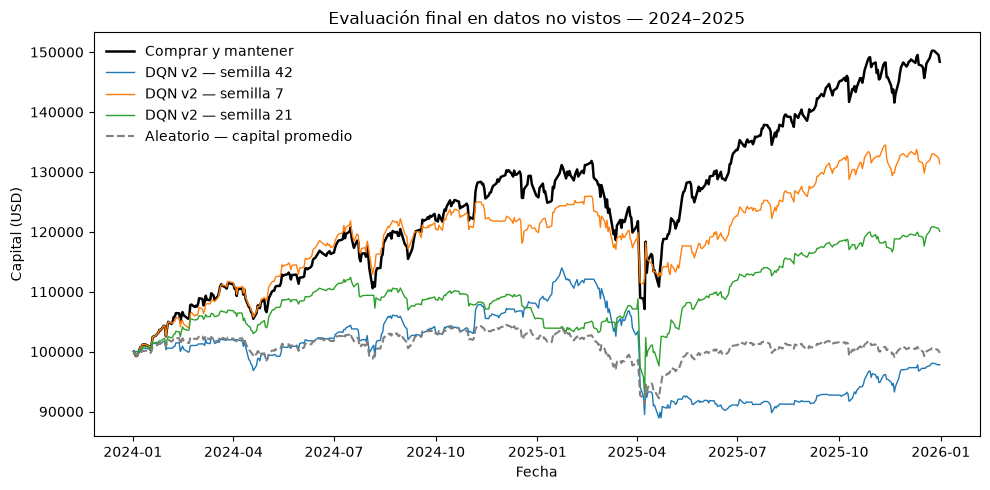

In [97]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(10, 5))

ax.plot(
    historial_compra_prueba["fecha"],
    historial_compra_prueba["capital"],
    color="black",
    linewidth=1.8,
    label="Comprar y mantener"
)

for semilla, historial in historiales_prueba.items():
    ax.plot(
        historial["fecha"],
        historial["capital"],
        linewidth=1,
        label=f"DQN v2 — semilla {semilla}"
    )

capital_aleatorio_promedio = np.column_stack(
    [
        historial["capital"].to_numpy()
        for historial in historiales_aleatorios_prueba.values()
    ]
).mean(axis=1)

ax.plot(
    historial_compra_prueba["fecha"],
    capital_aleatorio_promedio,
    color="gray",
    linestyle="--",
    label="Aleatorio — capital promedio"
)

ax.set_title("Evaluación final en datos no vistos — 2024–2025")
ax.set_xlabel("Fecha")
ax.set_ylabel("Capital (USD)")
ax.legend(frameon=False)

fig.tight_layout()
fig.savefig(
    resultados / "09_capital_prueba_final.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [99]:
comparacion_final.to_csv(
    resultados / "comparacion_final_prueba.csv"
)

tabla_dqn_prueba.to_csv(
    resultados / "metricas_dqn_prueba_semillas.csv"
)

tabla_aleatorios_prueba.to_csv(
    resultados / "metricas_aleatorios_prueba_semillas.csv"
)

historial_compra_prueba.to_csv(
    resultados / "historial_compra_prueba.csv",
    index=False
)

print("Evaluación final guardada.")

Evaluación final guardada.


In [101]:
display(tabla_dqn_prueba.round(2))

,Capital final (USD),Retorno acumulado (%),Máximo drawdown (%),Costos totales (USD)
Semilla,,,,
42,97804.23,-2.20,22.00,14910.60
7,131358.58,31.36,11.63,12306.06
21,120085.60,20.09,17.59,9371.61


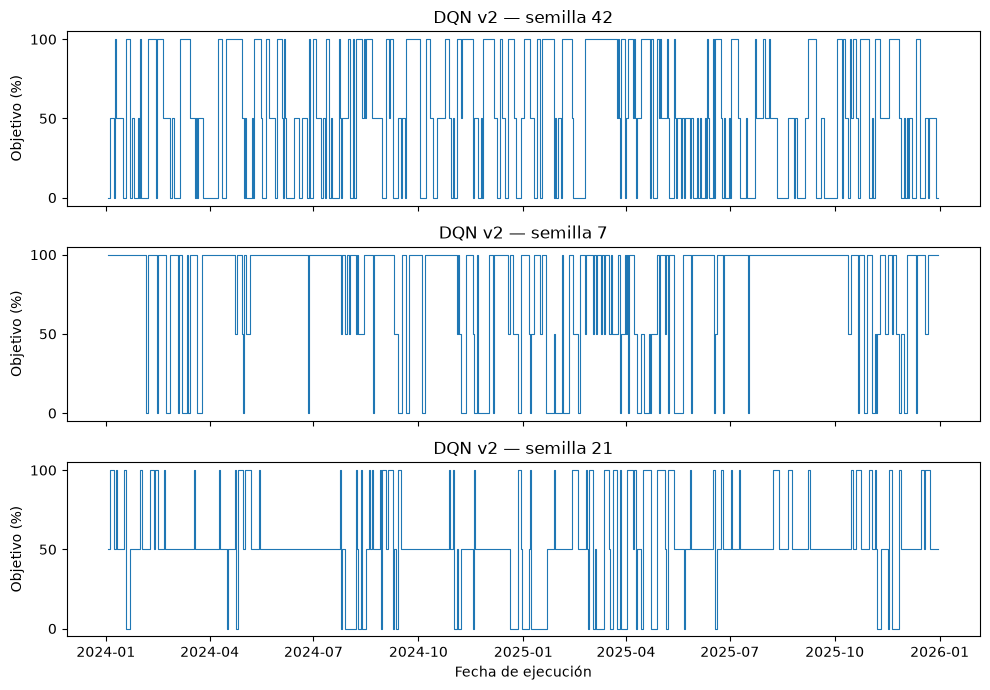

In [103]:
fig, axes = plt.subplots(
    3, 1,
    figsize=(10, 7),
    sharex=True
)

for ax, semilla in zip(axes, SEMILLAS):
    historial = historiales_prueba[semilla].iloc[1:]

    ax.step(
        historial["fecha"],
        historial["objetivo"] * 100,
        where="post",
        linewidth=0.8
    )

    ax.set_yticks([0, 50, 100])
    ax.set_ylabel("Objetivo (%)")
    ax.set_title(f"DQN v2 — semilla {semilla}")

axes[-1].set_xlabel("Fecha de ejecución")

fig.tight_layout()
fig.savefig(
    resultados / "10_posiciones_prueba_final.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [105]:
diagnostico_prueba = pd.DataFrame(
    [
        diagnostico_operaciones(historiales_prueba[semilla])
        for semilla in SEMILLAS
    ],
    index=SEMILLAS
)

diagnostico_prueba.index.name = "Semilla"

display(diagnostico_prueba.round(2))

diagnostico_prueba.to_csv(
    resultados / "diagnostico_operaciones_prueba.csv"
)

,Cambios de acción,Días con operación > 0.01 USD,Importe total operado (USD),Costos totales (USD)
Semilla,,,,
42,235,290,14910603.32,14910.60
7,144,163,12306062.41,12306.06
21,140,422,9371610.89,9371.61


In [107]:
historial_42 = historiales_prueba[42].reset_index(drop=True)

indice_peor_dia = historial_42["retorno_neto"].iloc[1:].idxmin()

inicio = max(0, indice_peor_dia - 2)
fin = min(len(historial_42), indice_peor_dia + 3)

print("Entorno de la mayor pérdida diaria — semilla 42:")

display(
    historial_42.iloc[inicio:fin][
        [
            "fecha",
            "accion",
            "objetivo",
            "posicion",
            "capital",
            "costo",
            "retorno_neto"
        ]
    ]
)

historial_42.iloc[inicio:fin].to_csv(
    resultados / "caso_perdida_semilla42.csv",
    index=False
)

Entorno de la mayor pérdida diaria — semilla 42:


,fecha,accion,objetivo,posicion,capital,costo,retorno_neto
313,2025-04-02,1,0.5,0.504229,103385.062729,0.110522,0.003191
314,2025-04-03,2,1.0,1.000000,99974.886441,51.204079,-0.032985
315,2025-04-04,2,1.0,1.000000,94122.068927,0.000000,-0.058543
316,2025-04-07,1,0.5,0.507644,92493.346490,45.585225,-0.017304
317,2025-04-08,2,1.0,1.000000,89499.881914,45.494146,-0.032364


In [109]:
import sys
from importlib.metadata import version

paquetes = [
    "numpy",
    "pandas",
    "scipy",
    "matplotlib",
    "scikit-learn",
    "gymnasium",
    "stable-baselines3",
    "torch",
    "yfinance",
    "joblib",
    "ipykernel"
]

dependencias = [
    f"{paquete}=={version(paquete)}"
    for paquete in paquetes
]

Path("requirements.txt").write_text(
    "\n".join(dependencias) + "\n",
    encoding="utf-8"
)

print("Versión de Python:", sys.version.split()[0])
print("Dependencias guardadas en requirements.txt.")

Versión de Python: 3.11.17
Dependencias guardadas en requirements.txt.
